In [3]:
!pip install qiskit
import qiskit
print(qiskit)
s = "110"

<module 'qiskit' from '/usr/local/lib/python3.13/dist-packages/qiskit/__init__.py'>


In [4]:
from qiskit import QuantumCircuit


def create_simon_oracle(secret):
    n = len(secret)

    # 2n qubits:
    # first n  -> input register
    # second n -> output register
    oracle = QuantumCircuit(2 * n)

    # Simple Simon function construction.
    # For each i where secret[i] == 1,
    # use the first 1-position as a reference.

    pivot = secret.find("1")

    if pivot == -1:
        # All-zero secret: use identity oracle
        return oracle

    # Copy the pivot input bit into corresponding output bit
    oracle.cx(pivot, n + pivot)

    for i in range(n):
        if i != pivot:
            oracle.cx(i, n + i)

    # Modify the oracle so that inputs differing by s
    # produce the same function value.
    for i in range(n):
        if secret[i] == "1" and i != pivot:
            oracle.cx(pivot, n + i)

    return oracle

In [5]:
from qiskit import QuantumCircuit


def build_function_table(secret):
    n = len(secret)
    s = int(secret, 2)

    table = {}
    output = 0

    for x in range(2 ** n):
        partner = x ^ s

        if x not in table and partner not in table:
            value = output
            output += 1

            table[x] = value
            table[partner] = value

    return table

In [6]:
secret = "110"

table = build_function_table(secret)

for x, value in sorted(table.items()):
    print(f"{x:03b} -> {value:03b}")

000 -> 000
001 -> 001
010 -> 010
011 -> 011
100 -> 010
101 -> 011
110 -> 000
111 -> 001


In [7]:
def verify_oracle(secret, table):
    n = len(secret)
    s = int(secret, 2)

    for x in range(2 ** n):
        partner = x ^ s

        if table[x] != table[partner]:
            return False

    return True


secret = "110"
table = build_function_table(secret)

print("Oracle correct:", verify_oracle(secret, table))

Oracle correct: True


In [8]:
from qiskit import QuantumCircuit


def create_simon_circuit(secret):
    n = len(secret)

    qc = QuantumCircuit(2 * n, n)

    # Step 1: Put first register into superposition
    for i in range(n):
        qc.h(i)

    # Step 2: Oracle
    oracle = create_simon_oracle(secret)
    qc.compose(oracle, inplace=True)

    # Step 3: Hadamard on input register
    for i in range(n):
        qc.h(i)

    # Step 4: Measure input register
    qc.measure(range(n), range(n))

    return qc

In [9]:
def gf2_solve(equations, n):
    """
    Solve A*x = 0 over GF(2).

    equations: list of bitstrings
    n: number of variables
    """

    A = [
        [int(bit) for bit in equation]
        for equation in equations
    ]

    rows = len(A)
    pivot_cols = []
    row = 0

    # Gaussian elimination
    for col in range(n):

        pivot = None

        for r in range(row, rows):
            if A[r][col] == 1:
                pivot = r
                break

        if pivot is None:
            continue

        A[row], A[pivot] = A[pivot], A[row]

        # Eliminate this column from all other rows
        for r in range(rows):
            if r != row and A[r][col] == 1:
                for c in range(col, n):
                    A[r][c] ^= A[row][c]

        pivot_cols.append(col)
        row += 1

    # Find free variables
    free_cols = [
        c for c in range(n)
        if c not in pivot_cols
    ]

    if not free_cols:
        return "0" * n

    # Choose first free variable = 1
    solution = [0] * n
    free = free_cols[0]
    solution[free] = 1

    # Back substitute
    for r in range(len(pivot_cols) - 1, -1, -1):

        pivot_col = pivot_cols[r]

        value = 0

        for c in range(pivot_col + 1, n):
            value ^= A[r][c] & solution[c]

        solution[pivot_col] = value

    return ''.join(map(str, solution))

In [10]:
equations = [
    "110",
    "011"
]

print(gf2_solve(equations, 3))

111


In [11]:
import sympy as sp


def solve_gf2(equations):
    n = len(equations[0])

    A = sp.Matrix([
        [int(bit) for bit in eq]
        for eq in equations
    ])

    # Nullspace over GF(2)
    nullspace = A.nullspace(iszerofunc=lambda x: x % 2 == 0)

    return nullspace

In [12]:
secret = "1011"

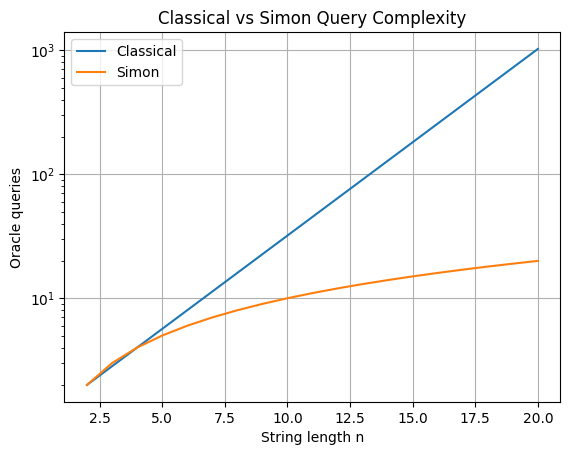

In [17]:
import math
import matplotlib.pyplot as plt

n_values = range(2, 21)

classical = [
    2 ** (n / 2)
    for n in n_values
]

quantum = [
    n
    for n in n_values
]

plt.plot(n_values, classical, label="Classical")
plt.plot(n_values, quantum, label="Simon")

plt.xlabel("String length n")
plt.ylabel("Oracle queries")
plt.title("Classical vs Simon Query Complexity")
plt.legend()
plt.grid()

plt.yscale("log") # Move this line here
plt.show()

In [19]:
def simon_algorithm(secret):
    # 1. Validate secret
    # 2. Construct oracle
    # 3. Run quantum circuit
    # 4. Collect independent equations
    # 5. Solve equations over GF(2)
    # 6. Return secret
    pass

In [20]:
if set(secret) == {"0"}:
    print("Secret is the all-zero string.")